# 02 · Componente supervisado: estimar la probabilidad de fraude
## Estrategia
- **Datos:** el entrenamiento se divide *por tiempo* en 80 % para ajustar y 20 % para **validar** (elegir el umbral). La prueba no se toca hasta el final.
- **Desbalance:** probamos Gradient Boosting con y sin pesos de clase para decidir con evidencia.
- **Métricas:** PR-AUC (principal), recall, precision, F1, ROC-AUC y matriz de confusión. La *accuracy* no sirve con tan poco fraude.
- **Umbral y selección del modelo:** se eligen con la validación, no con la prueba (evita fuga de información).

**Orden del notebook:** Bloque A (preparar los datos) → Bloque B (modelos) → Bloque C (resultados e interpretación).

---
# Bloque A · Preparar los datos
Cargamos la muestra del notebook 01 y separamos el entrenamiento en ajuste y validación, siempre por tiempo.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RAIZ = Path("..").resolve()            # raíz del repositorio
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp

DATA_DIR = RAIZ / "data" / "raw"       # CSV originales
PROC_DIR = RAIZ / "data" / "processed" # muestra dividida (del notebook 01)
RES_DIR = RAIZ / "resultados"          # métricas en JSON
SEED = 42
N_MUESTRA = int(os.environ.get("N_MUESTRA", 150_000))

In [2]:
train = pp.agregar_features(pd.read_pickle(PROC_DIR / "train.pkl"))
test = pp.agregar_features(pd.read_pickle(PROC_DIR / "test.pkl"))
num, cat, informe = pp.seleccionar_columnas(train)   # decidido solo con el train
cols = num + cat
print(f"train: {train.shape} | test: {test.shape} | variables usadas: {len(cols)}")

train: (105000, 437) | test: (45000, 437) | variables usadas: 311


In [3]:
corte = int(len(train) * 0.8)
tr_fit, tr_val = train.iloc[:corte], train.iloc[corte:]
Xf, yf = tr_fit[cols], tr_fit[pp.TARGET]
Xv, yv = tr_val[cols], tr_val[pp.TARGET]
Xt, yt = test[cols], test[pp.TARGET]
print(f"ajuste: {len(Xf):,} | validación: {len(Xv):,} | prueba: {len(Xt):,}")
print(f"Un modelo que no sabe nada tendría PR-AUC ≈ la tasa de fraude: {yt.mean():.3f}")

ajuste: 84,000 | validación: 21,000 | prueba: 45,000
Un modelo que no sabe nada tendría PR-AUC ≈ la tasa de fraude: 0.036


---
# Bloque B · Modelos
Primero justificamos los algoritmos, luego entrenamos los tres modelos base, definimos cómo medirlos y por último ajustamos el mejor.

## Justificación de los algoritmos
| Algoritmo | Por qué es apropiado | Supuestos | Ventajas | Limitaciones |
|---|---|---|---|---|
| **Regresión logística** | Línea base interpretable para clasificación binaria | Relación aproximadamente lineal entre variables y el log-odds | Rápida, coeficientes explicables | No captura interacciones ni relaciones no lineales |
| **Gradient Boosting (árboles)** | Funciona muy bien en datos tabulares con muchas variables y nulos | Casi ninguno sobre la distribución | Captura no linealidad e interacciones, tolera nulos | Más difícil de interpretar, riesgo de sobreajuste si no se ajusta |

**En palabras sencillas:** la regresión logística es el punto de partida: traza una frontera simple entre fraude y no fraude y deja ver qué variables pesan. Si el fraude dependiera solo de relaciones sencillas, bastaría con ella. Gradient Boosting construye muchos árboles pequeños, cada uno corrigiendo los errores del anterior, así que encuentra combinaciones que la logística no ve (por ejemplo, un monto normal solo es sospechoso con cierto tipo de tarjeta y dispositivo) y tolera los valores vacíos, que aquí son muchos. Por eso esperamos que gane Gradient Boosting, y la logística nos dice cuánto ganamos al complicar el modelo.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, precision_recall_curve, roc_curve, ConfusionMatrixDisplay)

modelos = {
    "Regresión logística": Pipeline([("pre", pp.preprocesador_lineal(num, cat)),
                                     ("clf", LogisticRegression(max_iter=500, class_weight="balanced"))]),
    "Gradient Boosting sin pesos": Pipeline([("pre", pp.preprocesador_arboles(num, cat)),
                                             ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
    "Gradient Boosting con pesos": Pipeline([("pre", pp.preprocesador_arboles(num, cat)),
                                             ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))]),
}
for nombre, m in modelos.items():
    m.fit(Xf, yf)
    print("entrenado:", nombre)

entrenado: Regresión logística
entrenado: Gradient Boosting sin pesos
entrenado: Gradient Boosting con pesos


### Umbral de decisión y métricas
Un modelo da una probabilidad de fraude; para decidir si bloquear hay que fijar un **umbral**. Aquí se elige en validación de dos formas: la que maximiza F1 (equilibrio entre precision y recall) o la que minimiza el costo total de errores (ver Bloque C).

In [5]:
COSTO_FN = 10   # SUPUESTO: dejar pasar un fraude cuesta 10 veces más que revisar una transacción legítima
COSTO_FP = 1

def mejor_umbral_f1(y, p):
    prec, rec, th = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(th[np.nanargmax(f1[:-1])])

def umbral_por_costo(y, p):
    grid = np.linspace(0.01, 0.99, 99)
    costos = [((p >= u) & (y == 0)).sum() * COSTO_FP + ((p < u) & (y == 1)).sum() * COSTO_FN for u in grid]
    return float(grid[int(np.argmin(costos))])

def metricas(y, p, umbral):
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "umbral": umbral, "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
            "costo": int(fp * COSTO_FP + fn * COSTO_FN)}

def evaluar(nombre, modelo, criterio="f1"):
    pv, pt = modelo.predict_proba(Xv)[:, 1], modelo.predict_proba(Xt)[:, 1]
    u = mejor_umbral_f1(yv, pv) if criterio == "f1" else umbral_por_costo(yv, pv)   # umbral elegido en VALIDACIÓN
    r = metricas(yt, pt, u)
    r["pr_auc_val"] = average_precision_score(yv, pv)   # PR-AUC en validación: criterio para elegir modelo
    return r, pt

resultados, probas = {}, {}
for nombre, m in modelos.items():
    resultados[nombre], probas[nombre] = evaluar(nombre, m)
pd.DataFrame(resultados).T[["pr_auc", "roc_auc", "precision", "recall", "f1", "umbral"]].round(3)

,pr_auc,roc_auc,precision,recall,f1,umbral
Regresión logística,0.216,0.821,0.388,0.295,0.335,0.931
Gradient Boosting sin pesos,0.475,0.868,0.652,0.369,0.471,0.286
Gradient Boosting con pesos,0.470,0.866,0.651,0.379,0.479,0.820


## Ajuste de hiperparámetros
Búsqueda aleatoria con **validación cruzada que respeta el tiempo** (`TimeSeriesSplit`) y PR-AUC como criterio. Se ajusta la variante con mejor PR-AUC en validación.

In [6]:
base = max(["Gradient Boosting sin pesos", "Gradient Boosting con pesos"], key=lambda n: resultados[n]["pr_auc_val"])
print("Variante que se ajusta:", base)
busqueda = RandomizedSearchCV(
    modelos[base],
    param_distributions={"clf__learning_rate": [0.03, 0.05, 0.1, 0.2], "clf__max_depth": [None, 4, 6, 8],
                         "clf__max_leaf_nodes": [15, 31, 63], "clf__l2_regularization": [0, 0.1, 1.0],
                         "clf__min_samples_leaf": [20, 50, 100]},
    n_iter=8, scoring="average_precision", cv=TimeSeriesSplit(3), random_state=SEED, n_jobs=-1, refit=True)
busqueda.fit(Xf, yf)
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"PR-AUC en validación cruzada: {busqueda.best_score_:.3f}")
modelos["Gradient Boosting ajustado"] = busqueda.best_estimator_
resultados["Gradient Boosting ajustado"], probas["Gradient Boosting ajustado"] = evaluar("ajustado", busqueda.best_estimator_)

Variante que se ajusta: Gradient Boosting sin pesos
Mejores hiperparámetros: {'clf__min_samples_leaf': 100, 'clf__max_leaf_nodes': 31, 'clf__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 1.0}
PR-AUC en validación cruzada: 0.531


---
# Bloque C · Resultados e interpretación
Evaluamos en la prueba (el futuro de la muestra), comparamos modelos, analizamos el costo de los errores y las variables más influyentes.

## Resultados en el conjunto de prueba

In [7]:
tabla = pd.DataFrame(resultados).T[["pr_auc_val", "pr_auc", "roc_auc", "precision", "recall", "f1", "umbral", "tp", "fp", "fn", "costo"]]
display(tabla.round(3))
mejor = max(resultados, key=lambda n: resultados[n]["pr_auc_val"])   # se elige con validación, no con prueba
print("Mejor modelo (PR-AUC en validación):", mejor)

,pr_auc_val,pr_auc,roc_auc,precision,recall,f1,umbral,tp,fp,fn,costo
Regresión logística,0.405,0.216,0.821,0.388,0.295,0.335,0.931,478.0,755.0,1144.0,12195.0
Gradient Boosting sin pesos,0.534,0.475,0.868,0.652,0.369,0.471,0.286,598.0,319.0,1024.0,10559.0
Gradient Boosting con pesos,0.516,0.470,0.866,0.651,0.379,0.479,0.820,615.0,329.0,1007.0,10399.0
Gradient Boosting ajustado,0.536,0.481,0.873,0.583,0.392,0.469,0.221,636.0,455.0,986.0,10315.0


Mejor modelo (PR-AUC en validación): Gradient Boosting ajustado


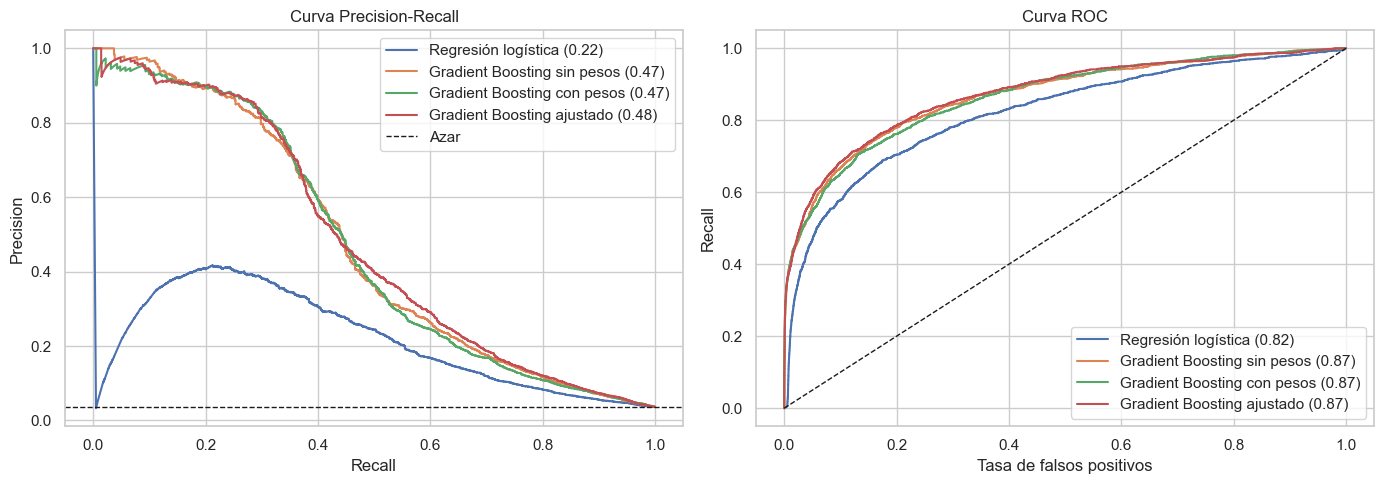

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for n, p in probas.items():
    pr, rc, _ = precision_recall_curve(yt, p); ax[0].plot(rc, pr, label=f"{n} ({resultados[n]['pr_auc']:.2f})")
    fpr, tpr, _ = roc_curve(yt, p); ax[1].plot(fpr, tpr, label=f"{n} ({resultados[n]['roc_auc']:.2f})")
ax[0].axhline(yt.mean(), color="k", ls="--", lw=1, label="Azar"); ax[0].set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set(xlabel="Tasa de falsos positivos", ylabel="Recall", title="Curva ROC")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

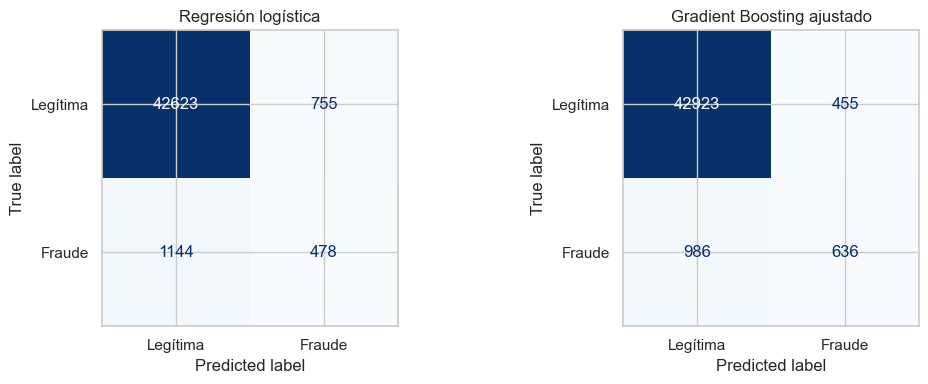

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, n in zip(ax, ["Regresión logística", mejor]):
    pred = (probas[n] >= resultados[n]["umbral"]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(yt, pred), display_labels=["Legítima", "Fraude"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(n)
plt.tight_layout(); plt.show()

## Costo de los errores
Un **falso negativo** es un fraude que pasa (pérdida de dinero y de confianza). Un **falso positivo** es una transacción legítima bloqueada o revisada (costo operativo y cliente molesto).
Con el supuesto `COSTO_FN = 10 × COSTO_FP`, comparamos el umbral que maximiza F1 con el que minimiza el costo total.

In [10]:
m = modelos[mejor]
pv = m.predict_proba(Xv)[:, 1]
u_costo = umbral_por_costo(yv, pv)
comparacion = pd.DataFrame({"Umbral que maximiza F1": resultados[mejor], "Umbral que minimiza costo": metricas(yt, probas[mejor], u_costo)}).T
display(comparacion[["umbral", "precision", "recall", "f1", "fp", "fn", "costo"]].round(3))

,umbral,precision,recall,f1,fp,fn,costo
Umbral que maximiza F1,0.221,0.583,0.392,0.469,455.0,986.0,10315.0
Umbral que minimiza costo,0.050,0.246,0.636,0.355,3167.0,590.0,9067.0


## Variables que más influyen (importancia por permutación)

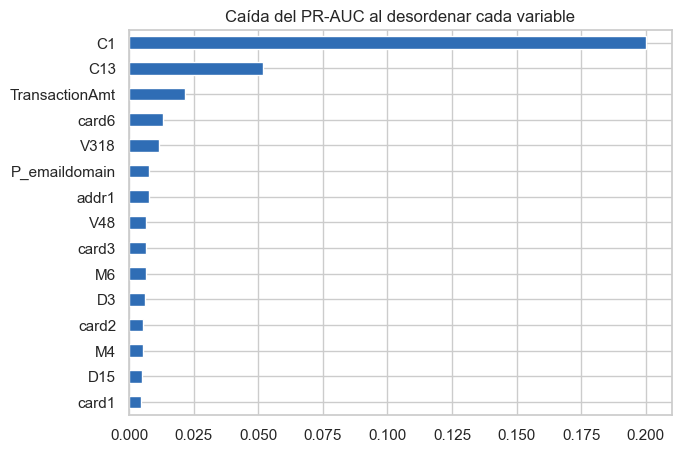

In [11]:
from sklearn.inspection import permutation_importance
pos = Xt[yt == 1].head(500); neg = Xt[yt == 0].sample(min(3500, int((yt == 0).sum())), random_state=SEED)
Xs = pd.concat([pos, neg]); ys = pd.concat([yt.loc[pos.index], yt.loc[neg.index]])
imp = permutation_importance(modelos[mejor], Xs, ys, scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
serie = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False).head(15)
serie.sort_values().plot(kind="barh", figsize=(7, 5), color="#2F6DB5")
plt.title("Caída del PR-AUC al desordenar cada variable"); plt.show()

In [12]:
RES_DIR.mkdir(exist_ok=True)
salida = {"prevalencia_test": float(yt.mean()), "mejor_modelo": mejor, "costos_supuestos": {"FN": COSTO_FN, "FP": COSTO_FP},
          "modelos": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in resultados.items()},
          "top_variables": serie.round(5).to_dict()}
(RES_DIR / "supervisado.json").write_text(json.dumps(salida, indent=2, ensure_ascii=False), encoding="utf-8")
print("guardado en resultados/supervisado.json")

guardado en resultados/supervisado.json


## Otras mejoras que probamos (no incorporadas)
Como el PR-AUC de unos 0,5 nos pareció bajo, probamos tres ideas aparte, con la misma prueba de 45.000 transacciones:
- **Más iteraciones y categorías nativas en Gradient Boosting:** el modelo base usa 100 iteraciones; con 600 y tratando las categóricas como categorías, el PR-AUC pasó de unos 0,48 a unos 0,49. La mejora es pequeña y no cambia las conclusiones, así que dejamos la configuración sencilla.
- **Más datos:** usar las 590.540 transacciones en lugar de 150.000 subió el PR-AUC de unos 0,49 a 0,52. Ayuda, pero poco, y exige mucha más memoria.
- **Variables por cliente:** identificamos a la misma tarjeta y calculamos cuántas transacciones previas tenía, cuánto tiempo pasó desde la última y si el monto era distinto al habitual (usando solo el pasado de cada transacción, sin fuga). No mejoró el resultado.

La conclusión es que, entrenando con el pasado y probando con el futuro, este tipo de modelo se queda alrededor de 0,5 de PR-AUC con estos datos. Los resultados mucho más altos de la competencia usaban información del futuro (por ejemplo, agrupar por cliente incluyendo el periodo de prueba), y eso aquí sería fuga de datos.

## Conclusiones del componente supervisado
- **Qué modelo ganó:** Gradient Boosting ajustado, elegido por su PR-AUC en validación (0,536). En la prueba logró PR-AUC de 0,481 y ROC-AUC de 0,873. Un modelo sin información tendría un PR-AUC de 0,036, así que el resultado es unas 13 veces mejor que el azar. La regresión logística, que usamos como punto de partida, llegó solo a 0,216: las relaciones entre las variables no son lineales y los árboles las capturan mucho mejor.
- **Qué tan bien detecta fraudes:** con el umbral que maximiza F1 (0,22), de cada 10 transacciones que el modelo marca como fraude, unas 6 lo son (precision 0,58), pero solo encuentra unos 4 de cada 10 fraudes reales (recall 0,39). Acierta bastante cuando avisa, pero deja pasar la mayoría de los fraudes.
- **Pesos de clase:** no ayudaron: el PR-AUC fue menor con pesos (0,470) que sin ellos (0,475); solo cambiaron el equilibrio entre precision y recall. **Ajuste de hiperparámetros:** la mejora fue pequeña (de 0,475 a 0,481 en la prueba), lo que indica que el límite está en la información de los datos más que en la configuración del modelo.
- **Variables que más pesan:** `C1` pesa mucho más que cualquier otra (cuando se desordena, el PR-AUC cae unos 0,20), seguida de `C13`, `TransactionAmt`, `card6` y `V318`. Según la descripción de la competencia, las variables `C` son conteos relacionados con la tarjeta, y los detalles no se publican, así que no podemos interpretarlas más. Que `card6` (crédito o débito), el monto y el correo del comprador aparezcan coincide con lo que vimos en el análisis exploratorio.
- **Costo de los errores:** con el supuesto de que un fraude que pasa cuesta 10 veces más que revisar una transacción legítima, el umbral que minimiza el costo (0,05) detecta el 64 % de los fraudes, a cambio de muchos más falsos positivos (3.167 contra 455) y una precision de 0,25. El costo total baja cerca de un 12 % frente al umbral de F1. Si el costo real fuera distinto de 10 a 1, el umbral recomendado cambiaría.
- **Limitaciones:** la prueba es el futuro de nuestra muestra y el fraude cambia con el tiempo (el PR-AUC fue 0,54 en validación y 0,48 en prueba); el costo de 10 a 1 es un supuesto; muchas variables son anónimas; y trabajamos con 150.000 de las 590.540 transacciones. Probamos también más iteraciones, más datos y variables por cliente, y el resultado se mantuvo en torno a 0,5.